# Exploratory Data Analysis (EDA)
## Vietnamese Medical Diagnosis Dataset - ANN Training

**Dataset:** `symptom_disease_dataset_7_converted.csv`  
**Purpose:** Analyze dataset characteristics for ANN architecture design  
**Date:** 2025-10-17  

---

## Objectives
1. Understand dataset structure and dimensions
2. Analyze disease distribution and class balance
3. Examine symptom frequency and patterns
4. Identify data quality issues
5. Provide recommendations for ANN training

## 1. Setup and Data Loading

In [1]:
%pip install pandas matplotlib seaborn scikit-learn -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings

warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Set figure size defaults
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


In [3]:
# Load dataset
DATA_PATH = '../data/symptom_disease_dataset_7_converted.csv'

df = pd.read_csv(DATA_PATH)

print(f"✅ Dataset loaded successfully")
print(f"   Shape: {df.shape}")
print(f"   Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

✅ Dataset loaded successfully
   Shape: (246945, 378)
   Memory usage: 737.69 MB


## 2. Dataset Overview

In [24]:
# Basic information
print("="*80)
print("DATASET OVERVIEW")
print("="*80)

print(f"\n📊 Dimensions:")
print(f"   Total samples: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")
print(f"   Total symptoms (features): {len(df.columns) - 1}")

print(f"\n🏥 Disease Information:")
print(f"   Unique diseases: {df['disease'].nunique()}")

print(f"\n📋 Data Types:")
print(df.dtypes.value_counts())

print(f"\n🔍 Missing Values:")
missing_total = df.isnull().sum().sum()
print(f"   Total missing: {missing_total}")
if missing_total == 0:
    print("    No missing values detected")

DATASET OVERVIEW

📊 Dimensions:
   Total samples: 246,945
   Total columns: 378
   Total symptoms (features): 377

🏥 Disease Information:
   Unique diseases: 768

📋 Data Types:
int64     377
object      1
Name: count, dtype: int64

🔍 Missing Values:
   Total missing: 0
    No missing values detected


In [5]:
# Display first few rows
print("\n📋 Sample Data (First 3 rows):")
print("="*80)
display(df.head(3))


📋 Sample Data (First 3 rows):


,disease,lo lắng và căng thẳng,trầm cảm,hụt hơi,các triệu chứng trầm cảm hoặc loạn thần,đau ngực dữ dội,chóng mặt,mất ngủ,các chuyển động không tự nguyện bất thường,tức ngực,...,nói lắp hoặc nói ngọng,vấn đề với cực khoái,dị dạng mũi,khối u trên hàm,đau ở mũi,yếu hông,sưng lưng,cứng hoặc căng mắt cá chân,yếu mắt cá chân,yếu cổ
0,rối loạn hoảng sợ,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,rối loạn hoảng sợ,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,rối loạn hoảng sợ,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
# Check for duplicates
print("="*80)
print("DUPLICATE ANALYSIS")
print("="*80)

duplicates = df.duplicated().sum()
duplicate_percentage = (duplicates / len(df)) * 100

print(f"\n  Duplicate Rows:")
print(f"   Count: {duplicates:,}")
print(f"   Percentage: {duplicate_percentage:.2f}%")

if duplicates > 0:
    print(f"\n     WARNING: Dataset contains {duplicate_percentage:.1f}% duplicates")
    print(f"    Recommendation: Remove duplicates before training")

DUPLICATE ANALYSIS

  Duplicate Rows:
   Count: 57,308
   Percentage: 23.21%

    Recommendation: Remove duplicates before training


## 3. Disease Distribution Analysis

In [26]:
# Disease frequency analysis
disease_counts = df['disease'].value_counts()

print("="*80)
print("DISEASE DISTRIBUTION")
print("="*80)

print(f"\n Summary Statistics:")
print(f"   Total unique diseases: {len(disease_counts)}")
print(f"   Most common disease: {disease_counts.index[0]} ({disease_counts.iloc[0]:,} samples)")
print(f"   Least common disease: {disease_counts.index[-1]} ({disease_counts.iloc[-1]:,} samples)")
print(f"   Mean samples per disease: {disease_counts.mean():.1f}")
print(f"   Median samples per disease: {disease_counts.median():.1f}")
print(f"   Std deviation: {disease_counts.std():.1f}")

print(f"\n Top 10 Most Common Diseases:")
print(disease_counts.head(10).to_string())

print(f"\n Bottom 10 Least Common Diseases:")
print(disease_counts.tail(10).to_string())

DISEASE DISTRIBUTION

 Summary Statistics:
   Total unique diseases: 768
   Most common disease: viêm thanh quản (1,582 samples)
   Least common disease: sốt thương hàn (1 samples)
   Mean samples per disease: 321.5
   Median samples per disease: 168.0
   Std deviation: 355.0

 Top 10 Most Common Diseases:
disease
viêm thanh quản                  1582
viêm bàng quang                  1219
rối loạn mũi                     1218
đau âm hộ                        1218
hội chứng đau vùng phức hợp      1217
bệnh thoái hóa cột sống          1216
u nang âm đạo                    1215
viêm kết mạc do dị ứng           1215
viêm thực quản                   1215
rối loạn thần kinh ngoại biên    1215

 Bottom 10 Least Common Diseases:
disease
vết thương hở ở đầu        1
Sốt màng não miền núi      1
tăng gammaglobulin máu     1
vết thương hở ở ngực       1
vết thương hở ở đầu gối    1
bệnh thalassemia           1
viêm cơ tim                1
loét mãn tính              1
vết thương hở ở má         1


In [27]:
# Class balance analysis
print("\n" + "="*80)
print("CLASS BALANCE ANALYSIS")
print("="*80)

# Group diseases by sample count ranges
bins = [0, 10, 50, 100, 500, 1000, 2000, float('inf')]
labels = ['1-9', '10-49', '50-99', '100-499', '500-999', '1000-1999', '2000+']

distribution = pd.cut(disease_counts, bins=bins, labels=labels).value_counts().sort_index()

print(f"\n Disease Distribution by Sample Count:")
for range_label, count in distribution.items():
    percentage = (count / len(disease_counts)) * 100
    print(f"   {range_label:12} samples: {count:4} diseases ({percentage:5.1f}%)")

# Identify severely imbalanced classes
rare_diseases = disease_counts[disease_counts < 10]
print(f"\n  Severely Under-represented Classes (<10 samples): {len(rare_diseases)} diseases")
print(f"   This represents {(len(rare_diseases)/len(disease_counts)*100):.1f}% of all diseases")


CLASS BALANCE ANALYSIS

 Disease Distribution by Sample Count:
   1-9          samples:  109 diseases ( 14.2%)
   10-49        samples:  136 diseases ( 17.7%)
   50-99        samples:   82 diseases ( 10.7%)
   100-499      samples:  241 diseases ( 31.4%)
   500-999      samples:  162 diseases ( 21.1%)
   1000-1999    samples:   38 diseases (  4.9%)
   2000+        samples:    0 diseases (  0.0%)

  Severely Under-represented Classes (<10 samples): 95 diseases
   This represents 12.4% of all diseases


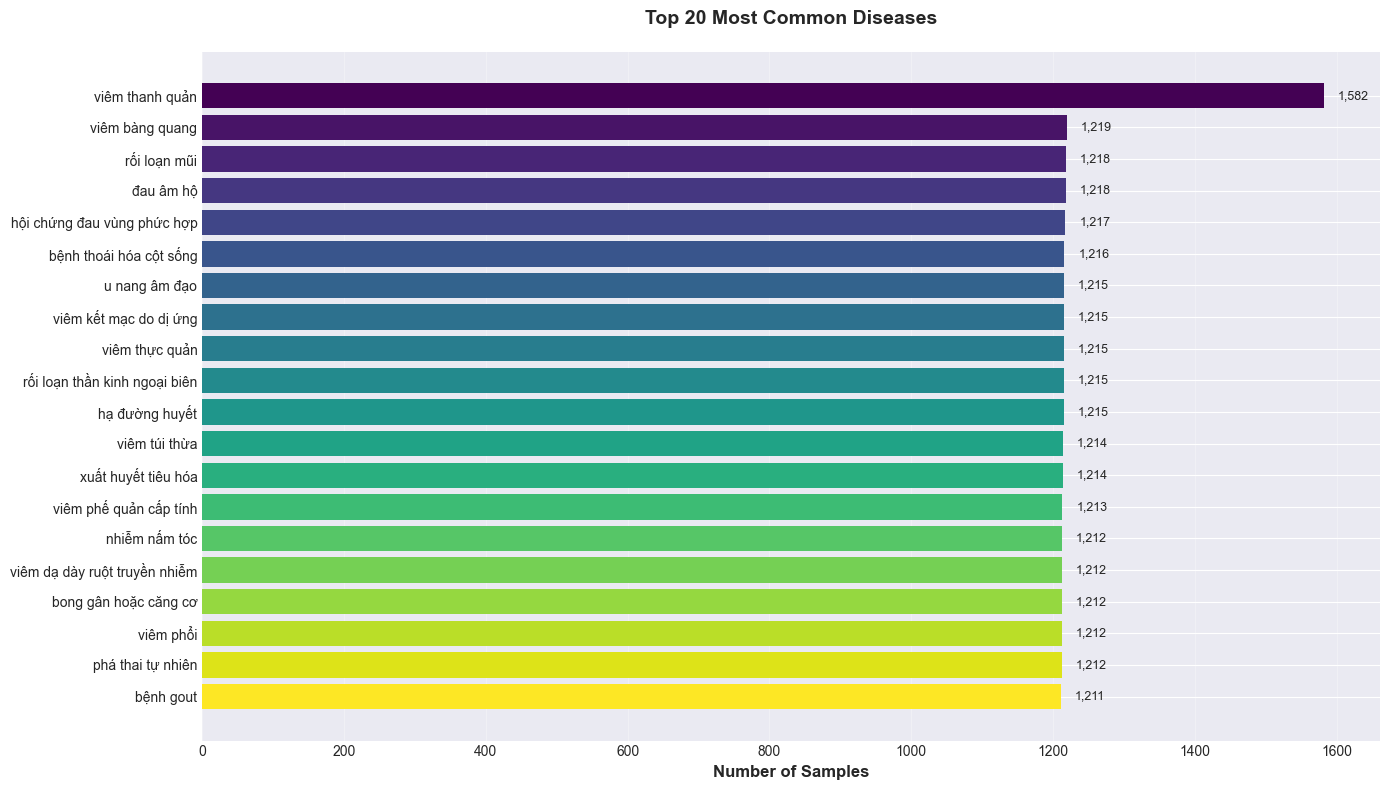

 Chart saved: data/eda_top20_diseases.png


In [28]:
# Visualization 1: Top 20 diseases bar chart
fig, ax = plt.subplots(figsize=(14, 8))

top_20 = disease_counts.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, 20))

bars = ax.barh(range(len(top_20)), top_20.values, color=colors)
ax.set_yticks(range(len(top_20)))
ax.set_yticklabels(top_20.index, fontsize=10)
ax.set_xlabel('Number of Samples', fontsize=12, fontweight='bold')
ax.set_title('Top 20 Most Common Diseases', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()

# Add value labels on bars
for i, (bar, value) in enumerate(zip(bars, top_20.values)):
    ax.text(value + 20, bar.get_y() + bar.get_height()/2, f'{value:,}', 
            va='center', fontsize=9)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../data/eda_top20_diseases.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_top20_diseases.png")

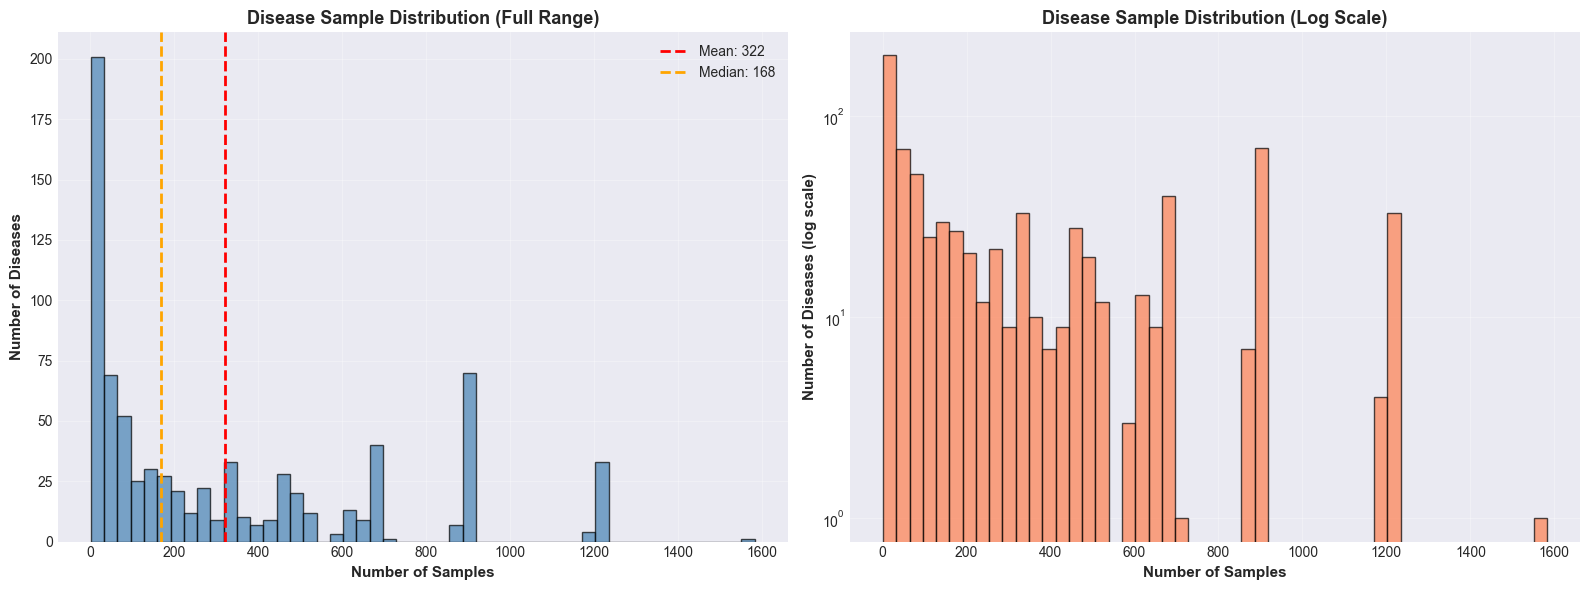

 Chart saved: data/eda_disease_distribution.png


In [29]:
# Visualization 2: Disease distribution histogram
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Full distribution
ax1.hist(disease_counts.values, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Number of Samples', fontsize=11, fontweight='bold')
ax1.set_ylabel('Number of Diseases', fontsize=11, fontweight='bold')
ax1.set_title('Disease Sample Distribution (Full Range)', fontsize=13, fontweight='bold')
ax1.axvline(disease_counts.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {disease_counts.mean():.0f}')
ax1.axvline(disease_counts.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {disease_counts.median():.0f}')
ax1.legend()
ax1.grid(alpha=0.3)

# Log scale for better visualization
ax2.hist(disease_counts.values, bins=50, color='coral', edgecolor='black', alpha=0.7)
ax2.set_xlabel('Number of Samples', fontsize=11, fontweight='bold')
ax2.set_ylabel('Number of Diseases (log scale)', fontsize=11, fontweight='bold')
ax2.set_title('Disease Sample Distribution (Log Scale)', fontsize=13, fontweight='bold')
ax2.set_yscale('log')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/eda_disease_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_disease_distribution.png")

## 4. Symptom Analysis

In [31]:
# Extract symptom columns
symptom_cols = df.columns[1:]  # All columns except 'disease'

print("="*80)
print("SYMPTOM ANALYSIS")
print("="*80)

print(f"\n Symptom Statistics:")
print(f"   Total symptoms (features): {len(symptom_cols)}")

# Calculate symptom frequencies
symptom_frequencies = df[symptom_cols].sum().sort_values(ascending=False)

print(f"   Most common symptom: {symptom_frequencies.index[0]} ({symptom_frequencies.iloc[0]:,} occurrences)")
print(f"   Least common symptom: {symptom_frequencies.index[-1]} ({symptom_frequencies.iloc[-1]:,} occurrences)")
print(f"   Mean frequency: {symptom_frequencies.mean():.1f}")
print(f"   Median frequency: {symptom_frequencies.median():.1f}")

SYMPTOM ANALYSIS

 Symptom Statistics:
   Total symptoms (features): 377
   Most common symptom: đau bụng dữ dội (32,307 occurrences)
   Least common symptom: yếu cổ (0 occurrences)
   Mean frequency: 3493.2
   Median frequency: 1797.0


In [32]:
# Symptoms per patient analysis
symptoms_per_patient = df[symptom_cols].sum(axis=1)

print(f"\n Symptoms per Patient:")
print(f"   Mean: {symptoms_per_patient.mean():.2f}")
print(f"   Median: {symptoms_per_patient.median():.0f}")
print(f"   Min: {symptoms_per_patient.min()}")
print(f"   Max: {symptoms_per_patient.max()}")
print(f"   Std: {symptoms_per_patient.std():.2f}")

# Calculate sparsity
total_possible_values = len(df) * len(symptom_cols)
total_ones = df[symptom_cols].sum().sum()
sparsity = (1 - (total_ones / total_possible_values)) * 100

print(f"\n  Data Sparsity:")
print(f"   Sparsity: {sparsity:.2f}%")
print(f"   Active features: {100 - sparsity:.2f}%")
print(f"   Average active symptoms per patient: {symptoms_per_patient.mean():.2f} out of {len(symptom_cols)}")


 Symptoms per Patient:
   Mean: 5.33
   Median: 5
   Min: 1
   Max: 12
   Std: 1.64

  Data Sparsity:
   Sparsity: 98.59%
   Active features: 1.41%
   Average active symptoms per patient: 5.33 out of 377


In [33]:
# Top 20 most common symptoms
print(f"\n Top 20 Most Common Symptoms:")
top_20_symptoms = symptom_frequencies.head(20)
for i, (symptom, count) in enumerate(top_20_symptoms.items(), 1):
    percentage = (count / len(df)) * 100
    print(f"   {i:2}. {symptom:40} : {count:6,} ({percentage:5.1f}%)")


 Top 20 Most Common Symptoms:
    1. đau bụng dữ dội                          : 32,307 ( 13.1%)
    2. nôn mửa                                  : 27,874 ( 11.3%)
    3. đau đầu                                  : 24,719 ( 10.0%)
    4. ho                                       : 24,296 (  9.8%)
    5. đau ngực dữ dội                          : 24,016 (  9.7%)
    6. buồn nôn                                 : 23,687 (  9.6%)
    7. đau lưng                                 : 21,809 (  8.8%)
    8. hụt hơi                                  : 21,346 (  8.6%)
    9. sốt                                      : 20,394 (  8.3%)
   10. chóng mặt                                : 17,272 (  7.0%)
   11. da xuất hiện bất thường                  : 16,425 (  6.7%)
   12. nghẹt mũi                                : 16,200 (  6.6%)
   13. đau chân                                 : 16,189 (  6.6%)
   14. sưng da                                  : 15,165 (  6.1%)
   15. các triệu chứng trầm cảm hoặc loạn thầ

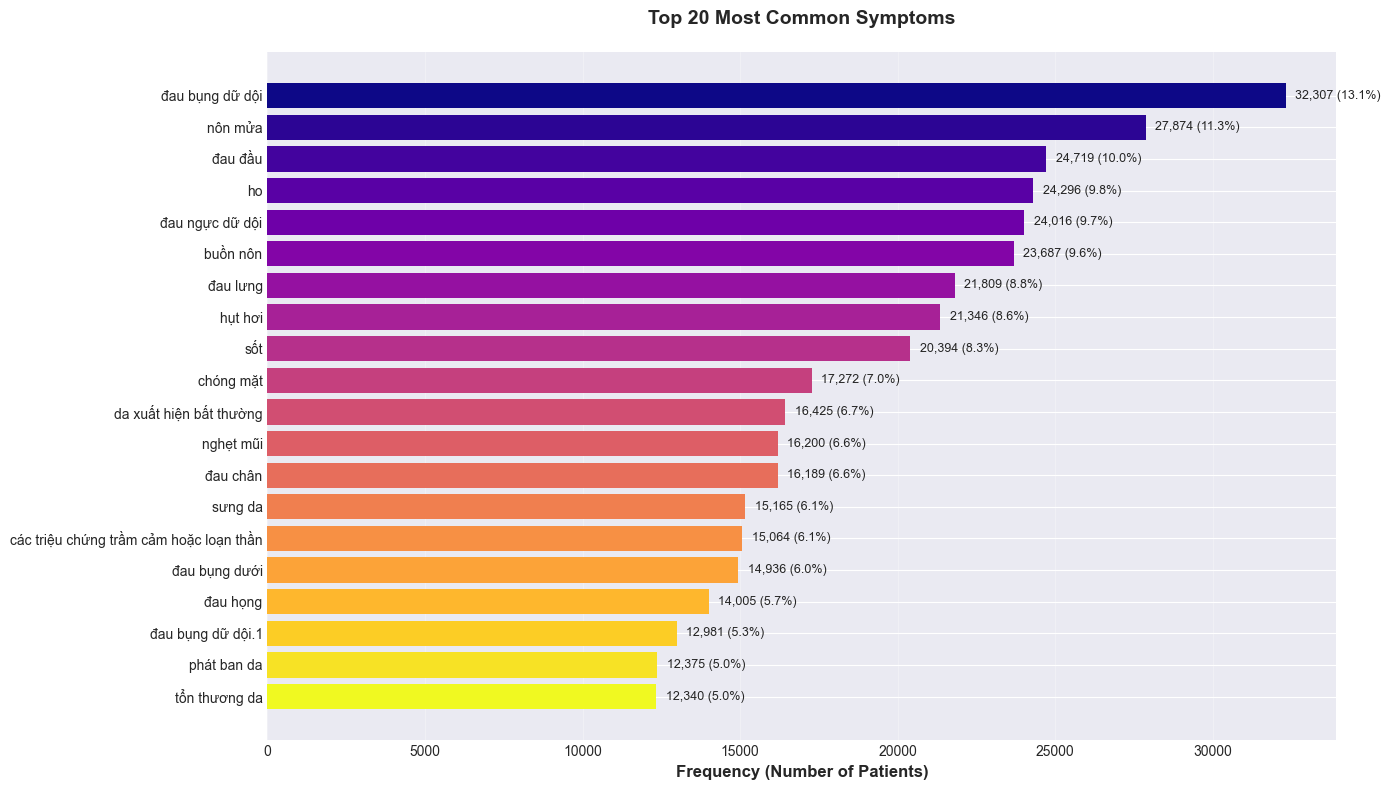

 Chart saved: data/eda_top20_symptoms.png


In [34]:
# Visualization 4: Top 20 symptoms bar chart
fig, ax = plt.subplots(figsize=(14, 8))

top_20_symptoms = symptom_frequencies.head(20)
colors = plt.cm.plasma(np.linspace(0, 1, 20))

bars = ax.barh(range(len(top_20_symptoms)), top_20_symptoms.values, color=colors)
ax.set_yticks(range(len(top_20_symptoms)))
ax.set_yticklabels(top_20_symptoms.index, fontsize=10)
ax.set_xlabel('Frequency (Number of Patients)', fontsize=12, fontweight='bold')
ax.set_title('Top 20 Most Common Symptoms', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()

# Add value labels
for i, (bar, value) in enumerate(zip(bars, top_20_symptoms.values)):
    percentage = (value / len(df)) * 100
    ax.text(value + 300, bar.get_y() + bar.get_height()/2, 
            f'{value:,} ({percentage:.1f}%)', va='center', fontsize=9)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../data/eda_top20_symptoms.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_top20_symptoms.png")

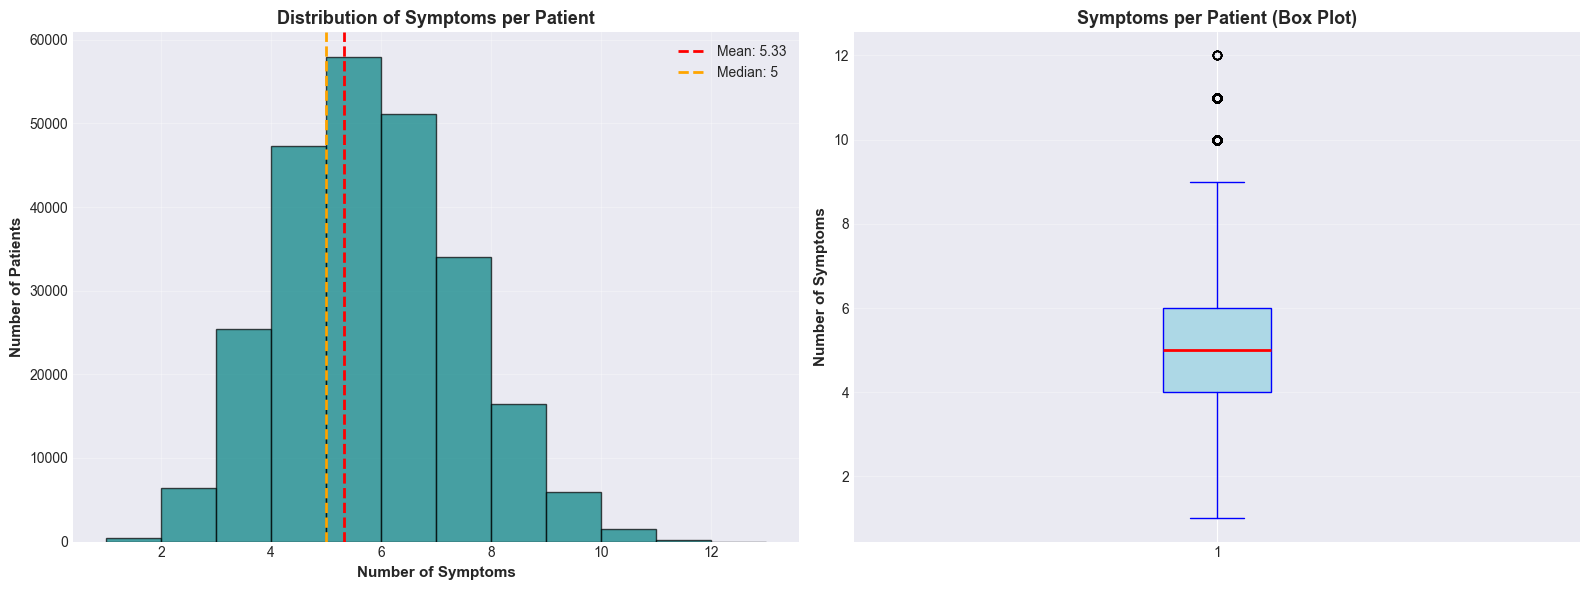

 Chart saved: data/eda_symptoms_per_patient.png


In [35]:
# Visualization 5: Symptoms per patient distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
ax1.hist(symptoms_per_patient, bins=range(1, symptoms_per_patient.max()+2), 
         color='teal', edgecolor='black', alpha=0.7)
ax1.axvline(symptoms_per_patient.mean(), color='red', linestyle='--', linewidth=2, 
            label=f'Mean: {symptoms_per_patient.mean():.2f}')
ax1.axvline(symptoms_per_patient.median(), color='orange', linestyle='--', linewidth=2, 
            label=f'Median: {symptoms_per_patient.median():.0f}')
ax1.set_xlabel('Number of Symptoms', fontsize=11, fontweight='bold')
ax1.set_ylabel('Number of Patients', fontsize=11, fontweight='bold')
ax1.set_title('Distribution of Symptoms per Patient', fontsize=13, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# Box plot
ax2.boxplot(symptoms_per_patient, vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='blue'),
            capprops=dict(color='blue'))
ax2.set_ylabel('Number of Symptoms', fontsize=11, fontweight='bold')
ax2.set_title('Symptoms per Patient (Box Plot)', fontsize=13, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../data/eda_symptoms_per_patient.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_symptoms_per_patient.png")

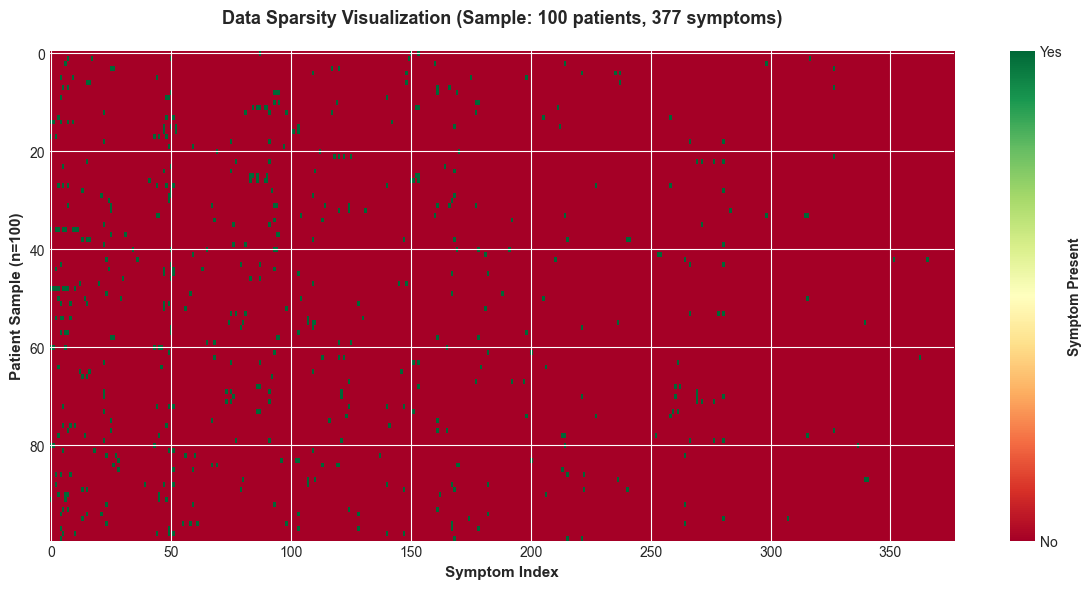

 Chart saved: data/eda_sparsity_heatmap.png

 Visual Interpretation:
   Green = Symptom present (1)
   Red = Symptom absent (0)
   Notice: Mostly red (sparse) with occasional green pixels


In [36]:
# Visualization 6: Sparsity visualization
fig, ax = plt.subplots(figsize=(12, 6))

# Sample 100 random patients to visualize sparsity pattern
sample_df = df[symptom_cols].sample(100, random_state=42)

# Create heatmap
im = ax.imshow(sample_df.values, aspect='auto', cmap='RdYlGn', interpolation='nearest')
ax.set_xlabel('Symptom Index', fontsize=11, fontweight='bold')
ax.set_ylabel('Patient Sample (n=100)', fontsize=11, fontweight='bold')
ax.set_title('Data Sparsity Visualization (Sample: 100 patients, 377 symptoms)', 
             fontsize=13, fontweight='bold', pad=20)

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Symptom Present', fontsize=10, fontweight='bold')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['No', 'Yes'])

plt.tight_layout()
plt.savefig('../data/eda_sparsity_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_sparsity_heatmap.png")
print(f"\n Visual Interpretation:")
print(f"   Green = Symptom present (1)")
print(f"   Red = Symptom absent (0)")
print(f"   Notice: Mostly red (sparse) with occasional green pixels")

## 5. Correlation Analysis (Sample)

In [37]:
# Correlation analysis for top 20 symptoms
print("="*80)
print("CORRELATION ANALYSIS (TOP 20 SYMPTOMS)")
print("="*80)

top_20_symptom_names = symptom_frequencies.head(20).index.tolist()
correlation_matrix = df[top_20_symptom_names].corr()

print(f"\n Correlation Matrix Shape: {correlation_matrix.shape}")
print(f"   Analyzing co-occurrence patterns among top 20 symptoms")

# Find strongest correlations (excluding diagonal)
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_pairs.append((
            correlation_matrix.columns[i],
            correlation_matrix.columns[j],
            correlation_matrix.iloc[i, j]
        ))

corr_pairs_sorted = sorted(corr_pairs, key=lambda x: abs(x[2]), reverse=True)

print(f"\n Top 10 Strongest Correlations:")
for i, (sym1, sym2, corr) in enumerate(corr_pairs_sorted[:10], 1):
    print(f"   {i:2}. {sym1[:30]:30} ↔ {sym2[:30]:30} : {corr:6.3f}")

CORRELATION ANALYSIS (TOP 20 SYMPTOMS)

 Correlation Matrix Shape: (20, 20)
   Analyzing co-occurrence patterns among top 20 symptoms

 Top 10 Strongest Correlations:
    1. da xuất hiện bất thường        ↔ sưng da                        :  0.374
    2. da xuất hiện bất thường        ↔ tổn thương da                  :  0.371
    3. sưng da                        ↔ tổn thương da                  :  0.348
    4. ho                             ↔ nghẹt mũi                      :  0.336
    5. nghẹt mũi                      ↔ đau họng                       :  0.312
    6. nôn mửa                        ↔ buồn nôn                       :  0.305
    7. ho                             ↔ sốt                            :  0.302
    8. da xuất hiện bất thường        ↔ phát ban da                    :  0.300
    9. ho                             ↔ đau họng                       :  0.295
   10. đau ngực dữ dội                ↔ hụt hơi                        :  0.291


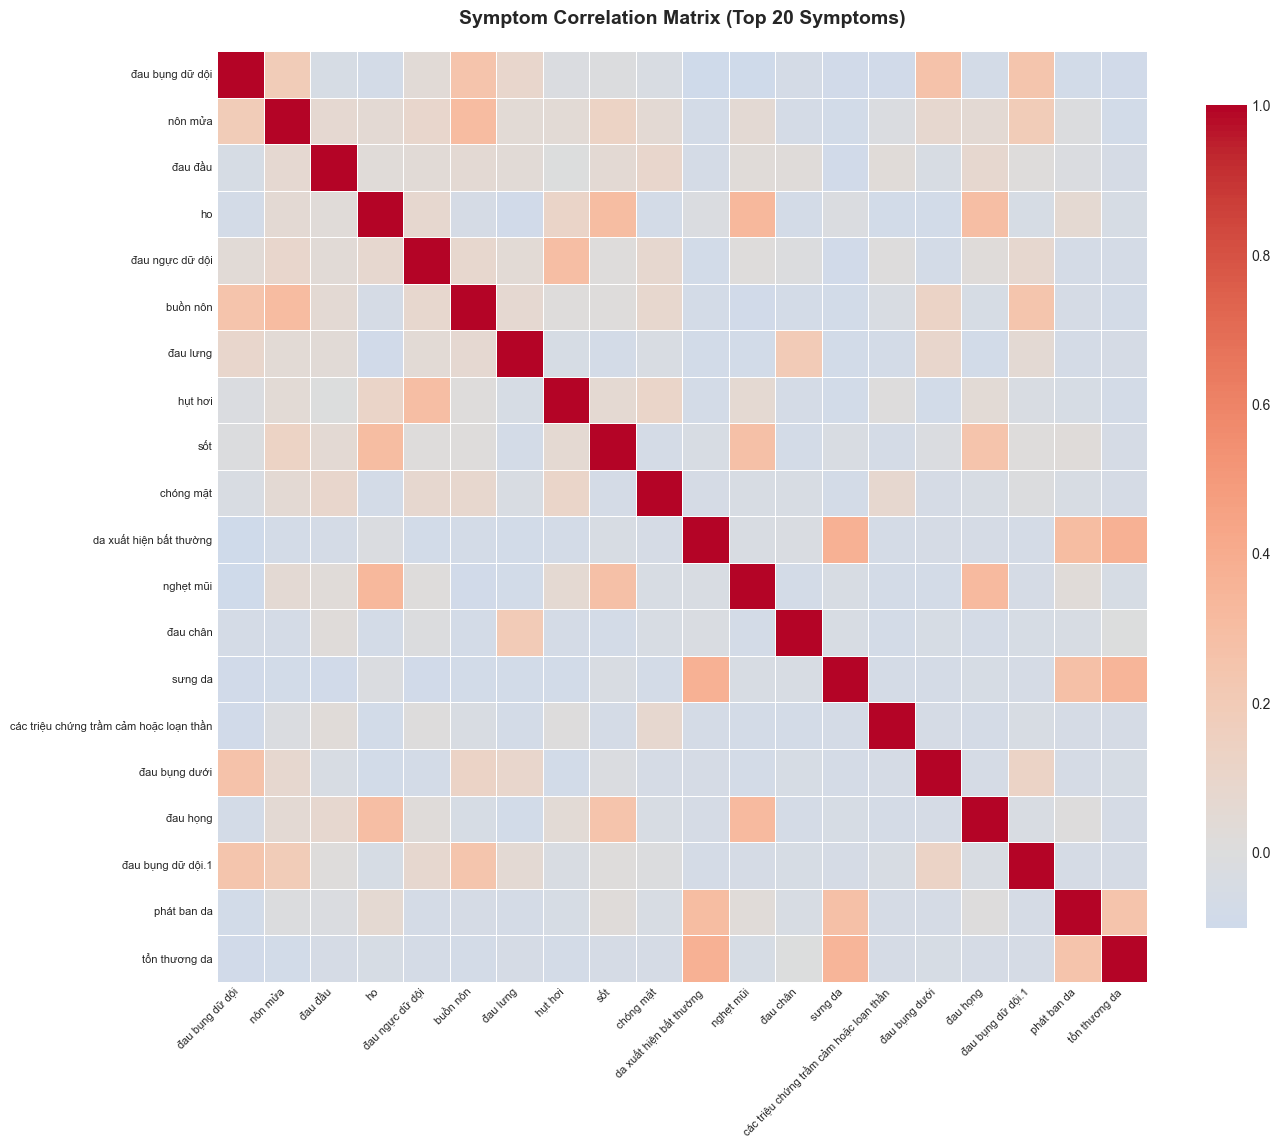

 Chart saved: data/eda_correlation_heatmap.png


In [38]:
# Visualization 7: Correlation heatmap (top 20 symptoms)
fig, ax = plt.subplots(figsize=(14, 12))

# Create heatmap with annotations
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            xticklabels=True, yticklabels=True, ax=ax)

ax.set_title('Symptom Correlation Matrix (Top 20 Symptoms)', 
             fontsize=14, fontweight='bold', pad=20)

# Rotate labels for better readability
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig('../data/eda_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart saved: data/eda_correlation_heatmap.png")

## 6. Data Quality Summary

In [40]:
print("="*80)
print("DATA QUALITY SUMMARY")
print("="*80)

print(f"\n STRENGTHS:")
print(f"   1. No missing values - Clean dataset")
print(f"   2. Binary encoding (0/1) - Perfect for neural networks")
print(f"   3. Fixed feature length ({len(symptom_cols)}) - Consistent input size")
print(f"   4. Large dataset ({len(df):,} samples) - Good for training")
print(f"   5. Rich feature space (377 symptoms) - Comprehensive coverage")

print(f"\n  CHALLENGES:")
print(f"   1. High sparsity ({sparsity:.2f}%) - May need special techniques")
print(f"   2. Severe class imbalance - {len(rare_diseases)} diseases have <10 samples")
print(f"   3. Many target classes (768) - Complex classification problem")
print(f"   4. Duplicate rows ({duplicate_percentage:.1f}%) - Need removal")
print(f"   5. High dimensionality - 377 features for ~5 active per sample")

print(f"\n PREPROCESSING REQUIREMENTS:")
print(f"    Remove {duplicates:,} duplicate rows")
print(f"    Stratified train/val/test split (preserve class distribution)")
print(f"    Consider class weights to handle imbalance")
print(f"    Monitor performance on rare disease classes")

print(f"\n DATASET READINESS:")
if duplicates == 0 and df.isnull().sum().sum() == 0:
    print(f"    Dataset is ready for training")
else:
    print(f"     Dataset requires preprocessing before training")

DATA QUALITY SUMMARY

 STRENGTHS:
   1. No missing values - Clean dataset
   2. Binary encoding (0/1) - Perfect for neural networks
   3. Fixed feature length (377) - Consistent input size
   4. Large dataset (246,945 samples) - Good for training
   5. Rich feature space (377 symptoms) - Comprehensive coverage

  CHALLENGES:
   1. High sparsity (98.59%) - May need special techniques
   2. Severe class imbalance - 95 diseases have <10 samples
   3. Many target classes (768) - Complex classification problem
   4. Duplicate rows (23.2%) - Need removal
   5. High dimensionality - 377 features for ~5 active per sample

 PREPROCESSING REQUIREMENTS:
    Remove 57,308 duplicate rows
    Stratified train/val/test split (preserve class distribution)
    Consider class weights to handle imbalance
    Monitor performance on rare disease classes

 DATASET READINESS:
     Dataset requires preprocessing before training


## 7. Recommendations for ANN Architecture

In [41]:
print("="*80)
print("RECOMMENDATIONS FOR ANN ARCHITECTURE")
print("="*80)

print(f"\n🏗️  ARCHITECTURE DESIGN:")
print(f"\n   1. Input Layer:")
print(f"      • Size: {len(symptom_cols)} neurons (one per symptom)")
print(f"      • Type: Binary inputs (0/1)")

print(f"\n   2. Hidden Layers:")
print(f"      • Recommended: 2-3 dense layers")
print(f"      • Sizes: 512 → 256 → 128 neurons")
print(f"      • Activation: ReLU")
print(f"      • Regularization: Dropout (0.3-0.4) to handle sparsity")
print(f"      • Normalization: Batch Normalization after each layer")

print(f"\n   3. Output Layer:")
print(f"      • Size: {len(disease_counts)} neurons (one per disease)")
print(f"      • Activation: Softmax (multi-class classification)")

print(f"\n  TRAINING STRATEGY:")
print(f"\n   1. Loss Function:")
print(f"      • Use Categorical Cross-Entropy with class weights")
print(f"      • Compute weights inversely proportional to class frequency")

print(f"\n   2. Optimizer:")
print(f"      • Adam optimizer with learning rate 0.001")
print(f"      • Consider learning rate scheduling (reduce on plateau)")

print(f"\n   3. Metrics:")
print(f"      • Accuracy (overall)")
print(f"      • Top-3 Accuracy (for ambiguous predictions)")
print(f"      • Macro F1-Score (handles class imbalance)")
print(f"      • Per-class precision/recall")

print(f"\n   4. Callbacks:")
print(f"      • Early Stopping (patience=10, monitor='val_loss')")
print(f"      • Model Checkpoint (save best model)")
print(f"      • Learning Rate Reduction (factor=0.5, patience=5)")

print(f"\n DATA SPLITTING:")
print(f"   • Train: 70% ({int(len(df)*0.7):,} samples)")
print(f"   • Validation: 15% ({int(len(df)*0.15):,} samples)")
print(f"   • Test: 15% ({int(len(df)*0.15):,} samples)")
print(f"   • Use stratified split to maintain class distribution")

print(f"\n EXPECTED CHALLENGES:")
print(f"   1. Sparse data may cause slow convergence")
print(f"      → Solution: Use higher dropout, batch normalization")
print(f"   2. Rare diseases may have poor accuracy")
print(f"      → Solution: Use class weights, monitor per-class metrics")
print(f"   3. 768 classes may cause overfitting")
print(f"      → Solution: Strong regularization, early stopping")
print(f"   4. High dimensional input (377 features)")
print(f"      → Solution: Proper initialization, batch normalization")

RECOMMENDATIONS FOR ANN ARCHITECTURE

🏗️  ARCHITECTURE DESIGN:

   1. Input Layer:
      • Size: 377 neurons (one per symptom)
      • Type: Binary inputs (0/1)

   2. Hidden Layers:
      • Recommended: 2-3 dense layers
      • Sizes: 512 → 256 → 128 neurons
      • Activation: ReLU
      • Regularization: Dropout (0.3-0.4) to handle sparsity
      • Normalization: Batch Normalization after each layer

   3. Output Layer:
      • Size: 768 neurons (one per disease)
      • Activation: Softmax (multi-class classification)

  TRAINING STRATEGY:

   1. Loss Function:
      • Use Categorical Cross-Entropy with class weights
      • Compute weights inversely proportional to class frequency

   2. Optimizer:
      • Adam optimizer with learning rate 0.001
      • Consider learning rate scheduling (reduce on plateau)

   3. Metrics:
      • Accuracy (overall)
      • Top-3 Accuracy (for ambiguous predictions)
      • Macro F1-Score (handles class imbalance)
      • Per-class precision/recall

## 8. Export Summary Statistics

In [42]:
# Create summary statistics dictionary
summary_stats = {
    'dataset_info': {
        'total_samples': len(df),
        'total_features': len(symptom_cols),
        'total_diseases': len(disease_counts),
        'duplicates': int(duplicates),
        'duplicate_percentage': float(duplicate_percentage),
        'sparsity_percentage': float(sparsity)
    },
    'disease_stats': {
        'most_common': disease_counts.index[0],
        'most_common_count': int(disease_counts.iloc[0]),
        'least_common': disease_counts.index[-1],
        'least_common_count': int(disease_counts.iloc[-1]),
        'mean_samples': float(disease_counts.mean()),
        'median_samples': float(disease_counts.median()),
        'rare_diseases_count': int(len(rare_diseases))
    },
    'symptom_stats': {
        'most_common': symptom_frequencies.index[0],
        'most_common_count': int(symptom_frequencies.iloc[0]),
        'mean_symptoms_per_patient': float(symptoms_per_patient.mean()),
        'median_symptoms_per_patient': float(symptoms_per_patient.median()),
        'min_symptoms': int(symptoms_per_patient.min()),
        'max_symptoms': int(symptoms_per_patient.max())
    }
}

# Save to JSON
import json
with open('../data/eda_summary_stats.json', 'w', encoding='utf-8') as f:
    json.dump(summary_stats, f, ensure_ascii=False, indent=2)

print(" Summary statistics saved: data/eda_summary_stats.json")
print(f"\n Summary Statistics:")
print(json.dumps(summary_stats, ensure_ascii=False, indent=2))

 Summary statistics saved: data/eda_summary_stats.json

 Summary Statistics:
{
  "dataset_info": {
    "total_samples": 246945,
    "total_features": 377,
    "total_diseases": 768,
    "duplicates": 57308,
    "duplicate_percentage": 23.20678693636235,
    "sparsity_percentage": 98.5854505451847
  },
  "disease_stats": {
    "most_common": "viêm thanh quản",
    "most_common_count": 1582,
    "least_common": "sốt thương hàn",
    "least_common_count": 1,
    "mean_samples": 321.54296875,
    "median_samples": 168.0,
    "rare_diseases_count": 95
  },
  "symptom_stats": {
    "most_common": "đau bụng dữ dội",
    "most_common_count": 32307,
    "mean_symptoms_per_patient": 5.3328514446536674,
    "median_symptoms_per_patient": 5.0,
    "min_symptoms": 1,
    "max_symptoms": 12
  }
}


## 9. Conclusion

In [43]:
print("="*80)
print("EDA CONCLUSION")
print("="*80)

print(f"\n ANALYSIS COMPLETE")
print(f"\n Key Findings:")
print(f"   1. Dataset contains {len(df):,} samples across {len(disease_counts)} diseases")
print(f"   2. Data is highly sparse ({sparsity:.1f}%) with avg {symptoms_per_patient.mean():.1f} symptoms/patient")
print(f"   3. Severe class imbalance exists (1 to 1,582 samples per disease)")
print(f"   4. {duplicate_percentage:.1f}% duplicates must be removed before training")
print(f"   5. Dataset structure is suitable for ANN but requires careful architecture design")

print(f"\n Generated Outputs:")
print(f"   ✓ 7 visualization charts saved in data/")
print(f"   ✓ Summary statistics exported to JSON")
print(f"   ✓ Comprehensive EDA report documented")

print(f"\n  NEXT STEPS:")
print(f"   1. Proceed to data preprocessing notebook")
print(f"   2. Remove duplicates and create train/val/test splits")
print(f"   3. Design and implement ANN architecture")
print(f"   4. Train model with recommended strategies")

print(f"\n" + "="*80)
print(f"END OF EXPLORATORY DATA ANALYSIS")
print(f"="*80)

EDA CONCLUSION

 ANALYSIS COMPLETE

 Key Findings:
   1. Dataset contains 246,945 samples across 768 diseases
   2. Data is highly sparse (98.6%) with avg 5.3 symptoms/patient
   3. Severe class imbalance exists (1 to 1,582 samples per disease)
   4. 23.2% duplicates must be removed before training
   5. Dataset structure is suitable for ANN but requires careful architecture design

 Generated Outputs:
   ✓ 7 visualization charts saved in data/
   ✓ Summary statistics exported to JSON
   ✓ Comprehensive EDA report documented

  NEXT STEPS:
   1. Proceed to data preprocessing notebook
   2. Remove duplicates and create train/val/test splits
   3. Design and implement ANN architecture
   4. Train model with recommended strategies

END OF EXPLORATORY DATA ANALYSIS
